/home/apal/.local/lib/python3.8/site-packages/pyproj/crs/crs.py:141: FutureWarning: '+init=<authority>:<code>' syntax is deprecated. '<authority>:<code>' is the preferred initialization method. When making the change, be mindful of axis order changes: https://pyproj4.github.io/pyproj/stable/gotchas.html#axis-order-changes-in-proj-6
  in_crs_string = _prepare_from_proj_string(in_crs_string)
/home/apal/.local/lib/python3.8/site-packages/pyproj/crs/crs.py:141: FutureWarning: '+init=<authority>:<code>' syntax is deprecated. '<authority>:<code>' is the preferred initialization method. When making the change, be mindful of axis order changes: https://pyproj4.github.io/pyproj/stable/gotchas.html#axis-order-changes-in-proj-6
  in_crs_string = _prepare_from_proj_string(in_crs_string)


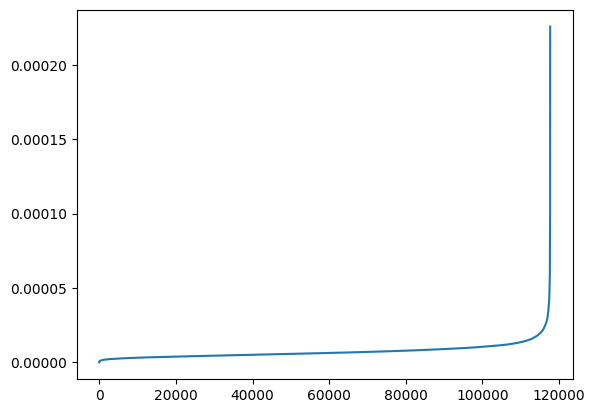

In [8]:
import shapely
import geopandas as gpd 
import argparse
import pandas as pd
import fiona 
from centroid_coords import *
import pdb
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from geopy.distance import great_circle
from shapely.geometry import MultiPoint
from sklearn.neighbors import NearestNeighbors




kms_per_radian = 6371.0088
eps = 0.5 / kms_per_radian
ms = 1
collection_change = list(fiona.open('/mnt/c/Users/apal72/Documents/Anisha/data/Henry_County_data/change_analysis/centroid_current_v_2006/centroids.shp','r'))
collection_str = list(fiona.open('/mnt/c/Users/apal72/Documents/Anisha/data/Henry_County_data/change_analysis/all_structures/centroids.shp','r'))
df1_change = pd.DataFrame(collection_change)
df1_str = pd.DataFrame(collection_str)

df1_change_new_field = add_fields(df1_change, 1)
df1_str_new_field = add_fields(df1_str, 0)

df1_change_coords = add_coords(df1_change_new_field)
df1_str_coords = add_coords(df1_str_new_field)
df_combined = pd.concat([df1_change_coords, df1_str_coords], ignore_index=True)
# pdb.set_trace()
# db = DBSCAN(eps=eps, min_samples=ms, algorithm='ball_tree', metric='haversine').fit(np.radians(df_combined[['lat','lon']]))
# print(db.labels)
neighbors = NearestNeighbors(n_neighbors=20)
neighbors_fit = neighbors.fit(np.radians(df_combined[['lat','lon']]))
distances, indices = neighbors_fit.kneighbors()
distances = np.sort(distances, axis=0)
distances = distances[:,1]
plt.plot(distances)
plt.show()

In [9]:
eps


7.848050688613081e-05